In [1]:
import sys
sys.path.append("..")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap
from src.data_loader import load_split, load_activity_labels

sns.set_theme()
RANDOM_STATE = 42

X_train, y_train, s_train = load_split("train")
labels = load_activity_labels()
y_names = y_train.map(labels).rename("activity")

scaler = StandardScaler().fit(X_train)       # learned from training data only
X_scaled = scaler.transform(X_train)
print(X_scaled.shape)

(7352, 561)


In [2]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

for target in [0.90, 0.95, 0.99]:
    n = int(np.argmax(cum_var >= target)) + 1
    print(f"{int(target * 100)}% of variance needs {n} components")

for k in [2, 10, 30, 100, 200]:
    print(f"{k:>3} components keep {cum_var[k - 1] * 100:.1f}% of variance")

print("First 5 component ratios:", pca_full.explained_variance_ratio_[:5].round(4))

90% of variance needs 63 components
95% of variance needs 102 components
99% of variance needs 179 components
  2 components keep 57.4% of variance
 10 components keep 70.8% of variance
 30 components keep 81.8% of variance
100 components keep 94.9% of variance
200 components keep 99.4% of variance
First 5 component ratios: [0.5078 0.0658 0.0281 0.025  0.0189]


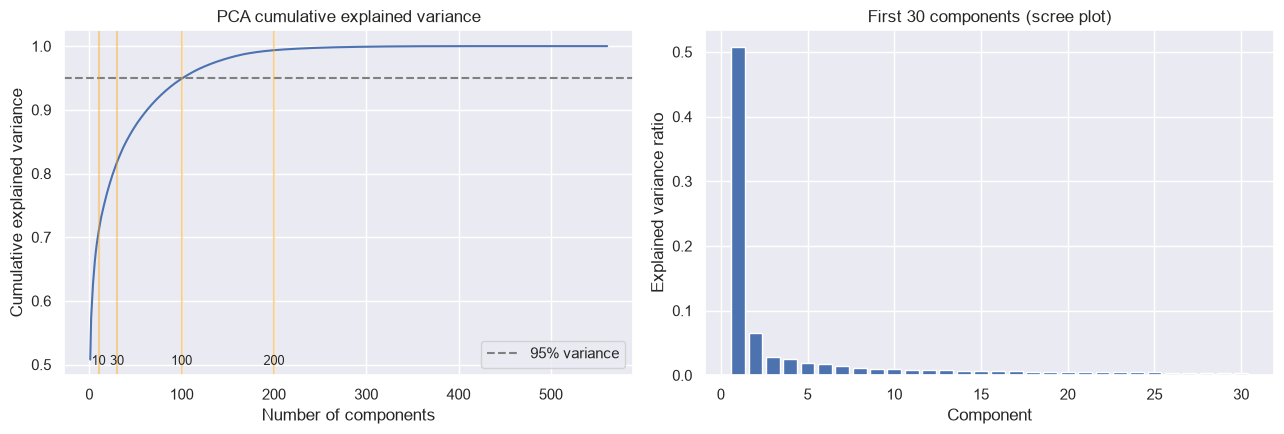

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(range(1, len(cum_var) + 1), cum_var)
axes[0].axhline(0.95, color="gray", linestyle="--", label="95% variance")
for k in [10, 30, 100, 200]:
    axes[0].axvline(k, color="orange", alpha=0.4)
    axes[0].text(k, 0.03, str(k), ha="center", fontsize=9, transform=axes[0].get_xaxis_transform())
axes[0].set_xlabel("Number of components")
axes[0].set_ylabel("Cumulative explained variance")
axes[0].set_title("PCA cumulative explained variance")
axes[0].legend(loc="lower right")

axes[1].bar(range(1, 31), pca_full.explained_variance_ratio_[:30])
axes[1].set_xlabel("Component")
axes[1].set_ylabel("Explained variance ratio")
axes[1].set_title("First 30 components (scree plot)")

plt.tight_layout()
plt.savefig("../reports/figures/pca_variance_curve.png", dpi=150)
plt.show()

In [5]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_scaled)
Z_pca = pca_2d.transform(X_scaled)
print("Variance kept by 2 components:", pca_2d.explained_variance_ratio_.sum().round(3))

Variance kept by 2 components: 0.574


In [6]:
X_pca50 = PCA(n_components=50, random_state=RANDOM_STATE).fit_transform(X_scaled)
print(X_pca50.shape, "variance kept:", cum_var[49].round(3))

(7352, 50) variance kept: 0.875


In [7]:
t0 = time.time()
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE)
Z_tsne = tsne.fit_transform(X_pca50)
print(f"t-SNE finished in {time.time() - t0:.0f}s")

t-SNE finished in 23s


In [8]:
t0 = time.time()
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE)
Z_umap = reducer.fit_transform(X_pca50)
print(f"UMAP finished in {time.time() - t0:.0f}s")

c:\Users\Vaishali\activitylens\venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP finished in 25s


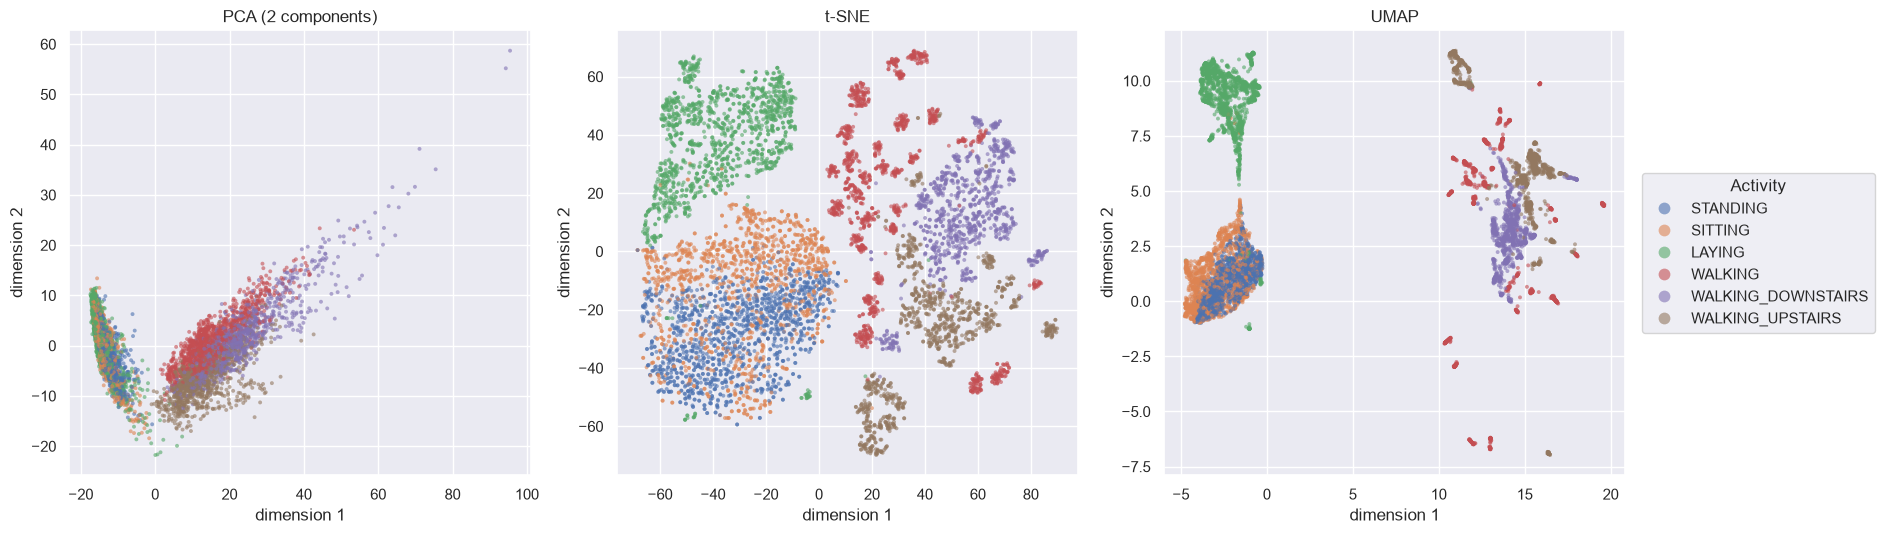

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
panels = [(Z_pca, "PCA (2 components)"), (Z_tsne, "t-SNE"), (Z_umap, "UMAP")]

for i, (ax, (Z, title)) in enumerate(zip(axes, panels)):
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=y_names, s=8, alpha=0.6, linewidth=0,
                    ax=ax, legend="full" if i == 2 else False)
    ax.set_title(title)
    ax.set_xlabel("dimension 1")
    ax.set_ylabel("dimension 2")

axes[2].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), markerscale=3, title="Activity")
plt.tight_layout()
plt.savefig("../reports/figures/dim_reduction_comparison.png", dpi=150, bbox_inches="tight")
plt.show()